# Laboratorio: Más películas o más series para Netflix?

**Pregunta de negocio:** Si vamos a ampliar el catálogo, **¿qué formato y qué géneros conviene explorar primero?**

Tu papel: analista del equipo de contenidos. Entregarás **5 gráficas**, un diagnóstico y una **propuesta de valor** fundamentada en un dataset público.

**Fuente:** [Netflix Movies and TV Shows en GitHub](https://github.com/japnitahuja/netflix-data-analysis/blob/main/netflix_titles.csv) (8,807 títulos; información histórica hasta septiembre de 2021).

**Tecnologias:** PySpark prepara los datos con filtros, `groupBy`, `when`, `avg` y `pivot`; **Pandas** recibe solo tablas resumidas; **Matplotlib** crea las gráficas. Cada ejercicio plantea una pregunta de negocio.

**Colab:** Abre el cuaderno en Google Colab y ejecuta las celdas en orden. La instalación y la descarga son automáticas; no es necesario montar Drive.

> **Limitacion:** esta fotografía muestra **oferta histórica**, no demanda. No contiene reproducciones, retención, presupuestos ni títulos que ya fueron retirados. La recomendación final será una hipótesis para validar, no una decisión definitiva de inversión.

## Preparación (no es un ejercicio)

La siguiente celda instala PySpark en el entorno de Colab; Matplotlib y Pandas normalmente ya vienen instalados. Spark 4 requiere **Java 17 o superior**. La sesión de Spark se ejecutará de forma local dentro de Colab (`local[*]`).

In [126]:
import sys
import subprocess

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "pyspark>=4.0,<4.2"],
    check=True
)
print("PySpark instalado. Si Python pide reiniciar el entorno, reinícialo y continúa.")


PySpark instalado. Si Python pide reiniciar el entorno, reinícialo y continúa.


In [127]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Laboratorio-Netflix-PySpark-Colab")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Versión de Spark:", spark.version)
print("Versión de Java:")
subprocess.run(["java", "-version"], check=True)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

ROJO = "#E50914"
AZUL = "#2874A6"
COLOR_MOVIE = ROJO
COLOR_SHOW = AZUL


Versión de Spark: 4.0.4
Versión de Java:


### Descargar y cargar el CSV directamente desde GitHub

El archivo se descarga a `/content` (disco temporal de Colab). **La lectura y limpieza se hacen en PySpark**, no en Pandas. Usamos un esquema explícito para evitar que diferentes versiones de Spark infieran distintos tipos. `multiLine=True` y `escape='"'` ayudan con descripciones que contienen comillas y saltos de línea.

In [128]:
URL = "https://raw.githubusercontent.com/japnitahuja/netflix-data-analysis/main/netflix_titles.csv"
RUTA = "/content/netflix_titles.csv" if os.path.isdir("/content") else "/tmp/netflix_titles.csv"

urllib.request.urlretrieve(URL, RUTA)
print("CSV descargado:", RUTA)
print("Tamaño (MB):", round(os.path.getsize(RUTA) / 1_000_000, 2))

columnas = [
    "show_id", "type", "title", "director", "cast", "country",
    "date_added", "release_year", "rating", "duration",
    "listed_in", "description"
]
esquema = StructType([StructField(c, StringType(), True) for c in columnas])

df_raw = (
    spark.read
    .option("header", "true")
    .option("multiLine", "true")
    .option("quote", '"')
    .option("escape", '"')
    .schema(esquema)
    .csv(RUTA)
)

filas_originales = df_raw.count()
print("Títulos cargados:", filas_originales)
assert filas_originales > 7000, "No se han cargado suficientes registros; revisa el CSV."
df_raw.select("show_id", "type", "title", "country", "duration").show(7, truncate=32)


CSV descargado: /content/netflix_titles.csv
Tamaño (MB): 3.4
Títulos cargados: 8807
+-------+-------+--------------------------------+-------------+---------+
|show_id|   type|                           title|      country| duration|
+-------+-------+--------------------------------+-------------+---------+
|     s1|  Movie|            Dick Johnson Is Dead|United States|   90 min|
|     s2|TV Show|                   Blood & Water| South Africa|2 Seasons|
|     s3|TV Show|                       Ganglands|         NULL| 1 Season|
|     s4|TV Show|           Jailbirds New Orleans|         NULL| 1 Season|
|     s5|TV Show|                    Kota Factory|        India|2 Seasons|
|     s6|TV Show|                   Midnight Mass|         NULL| 1 Season|
|     s7|  Movie|My Little Pony: A New Generation|         NULL|   91 min|
+-------+-------+--------------------------------+-------------+---------+
only showing top 7 rows


```text
5. Lo más común, en una línea cada uno

filter / where: se queda solo con las filas que cumplen la condición.
groupBy(...).agg(...): agrupa filas por una o más columnas y calcula una métrica por grupo.
orderBy: ordena el resultado.
F.when(...).otherwise(...): es un if/else por fila para crear una columna condicional.
cast("tipo"): cambia el tipo de una columna.
drop("col"): quita una columna.
alias("nombre"): le pone nombre a una columna calculada.
dropDuplicates([cols]): elimina filas repetidas según esas columnas.
fillna(valor): reemplaza nulos por un valor.
pivot: convierte los valores de una columna en columnas nuevas.
toPandas(): es una acción que trae el resultado al driver como DataFrame de pandas, por eso solo se usa con tablas chicas ya agregadas.
```

### Limpieza común en Spark

- Eliminamos identificadores nulos y títulos duplicados por `show_id`.
- Quitamos espacios sobrantes con `trim`.
- Convertimos `release_year` a entero.
- Dejamos los países y géneros como cadenas de texto hasta que cada ejercicio los necesite.

**Regla de arquitectura:** Spark realiza las transformaciones; sólo una tabla agregada o una muestra controlada pasa a Pandas para graficar.

In [129]:
print("Ver squema incial:")
df_raw.printSchema()
df_raw.show()

print("Limpieza:")


df = (
    df_raw
    .filter(F.col("show_id").isNotNull())
    .dropDuplicates(["show_id"])
    .select(
        "show_id",
        "title",
        "director",
        "cast",
        "rating",
        "duration",
        "description",
        F.trim("type").alias("type"),
        F.trim("country").alias("country"),
        F.trim("listed_in").alias("listed_in"),
        F.trim("date_added").alias("date_added"),
        F.trim("release_year").cast("int").alias("release_year"),
    )
)

print("Ver si hay nulos")
df.select(
    F.count(F.when(F.col("country").isNull(), True)).alias("country_nulos"),
    F.count(F.when(F.col("date_added").isNull(), True)).alias("date_added_nulos"),
    F.count(F.when(F.col("duration").isNull(), True)).alias("duration_nulos"),
    F.count(F.when(F.col("type").isNull(), True)).alias("type_nulos")
).show()


Ver squema incial:
root
 |-- show_id: string (nullable = true)
 |-- type: string (nullable = true)
 |-- title: string (nullable = true)
 |-- director: string (nullable = true)
 |-- cast: string (nullable = true)
 |-- country: string (nullable = true)
 |-- date_added: string (nullable = true)
 |-- release_year: string (nullable = true)
 |-- rating: string (nullable = true)
 |-- duration: string (nullable = true)
 |-- listed_in: string (nullable = true)
 |-- description: string (nullable = true)

+-------+-------+--------------------+--------------------+--------------------+--------------------+------------------+------------+------+---------+--------------------+--------------------+
|show_id|   type|               title|            director|                cast|             country|        date_added|release_year|rating| duration|           listed_in|         description|
+-------+-------+--------------------+--------------------+--------------------+--------------------+-------------

## Ejercicios

In [130]:
df.show(truncate=False)

+-------+-------------------------------+------------------------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------+---------+--------------------------------------------------------------------------------------------------------------------------------------------------------+-------+------------------------------+------------------------------------------------------------+------------------+------------+
|show_id|title                          |director                      |cast                                                                                                                                                                       |rating|duration |description                                                                                                                                             |type   |country                       |

In [131]:
df.count()

8807

In [132]:
df.select("listed_in").distinct().count()

514

In [133]:
df.where(F.col("listed_in").contains("Dramas")).select("listed_in").show(truncate=False)

+------------------------------------------------------------+
|listed_in                                                   |
+------------------------------------------------------------+
|Comedies, Dramas                                            |
|TV Comedies, TV Dramas                                      |
|Dramas, International Movies, Thrillers                     |
|Dramas, International Movies, Thrillers                     |
|International TV Shows, TV Comedies, TV Dramas              |
|International TV Shows, Spanish-Language TV Shows, TV Dramas|
|Dramas                                                      |
|Dramas, International Movies                                |
|Dramas, International Movies, Music & Musicals              |
|Comedies, Dramas, Independent Movies                        |
|Dramas, International Movies                                |
|Dramas, Independent Movies, International Movies            |
|Dramas, International Movies                          

In [134]:
es_dramas = F.col("listed_in").contains("Dramas") # Column
es_comedia = F.col("listed_in").contains("Comedies") # Column

df.select(
    F.col("*"),
    F.when(es_dramas,F.lit("Drama")).when(es_comedia,F.lit("Comedia")).otherwise("No es Drama").alias("Es Drama")
).show()

+-------+--------------------+--------------------+--------------------+------+---------+--------------------+-------+--------------------+--------------------+------------------+------------+-----------+
|show_id|               title|            director|                cast|rating| duration|         description|   type|             country|           listed_in|        date_added|release_year|   Es Drama|
+-------+--------------------+--------------------+--------------------+------+---------+--------------------+-------+--------------------+--------------------+------------------+------------+-----------+
|     s1|Dick Johnson Is Dead|     Kirsten Johnson|                NULL| PG-13|   90 min|As her father nea...|  Movie|       United States|       Documentaries|September 25, 2021|        2020|No es Drama|
|    s10|        The Starling|      Theodore Melfi|Melissa McCarthy,...| PG-13|  104 min|A woman adjusting...|  Movie|       United States|    Comedies, Dramas|September 24, 2021| 

### Una variable adicional para los ejercicios temporales

Creamos fecha de alta y año de incorporación con PySpark. Las fechas nulas se excluyen solo de los ejercicios que requieren una fecha.

In [135]:
df = (
    df.filter(F.col('type').isin('Movie', 'TV Show'))
      .withColumn('fecha_alta', F.to_date(F.col('date_added'), 'MMMM d, yyyy'))
      .withColumn('anio_alta', F.year(F.col('fecha_alta')))
)
df.cache()
print('Titulos validos:', df.count())
print('Sin fecha de alta:', df.filter(F.col('anio_alta').isNull()).count())

Titulos validos: 8807
Sin fecha de alta: 10


---
# Ejercicio 1/5: Películas vs. series

**Pregunta:** ¿Qué formato predomina en el catálogo? ¿Qué porcentaje representa cada uno?

**PySpark:** `filter`, `groupBy`, `count`, `orderBy`.

**Grafica:** barras de diferente color. La cantidad actual es una medida de **oferta**, no de preferencia del público.

In [136]:
to_porcentaje = df.groupBy("type").agg(F.count("type").alias("cantidad"))
to_porcentaje.show()
pd_to_porcentaje = to_porcentaje.toPandas()

+-------+--------+
|   type|cantidad|
+-------+--------+
|TV Show|    2676|
|  Movie|    6131|
+-------+--------+



# Graficalo

In [137]:
pd_to_porcentaje["porcentaje"] = 100 * pd_to_porcentaje["cantidad"] / pd_to_porcentaje["cantidad"].sum()
pd_to_porcentaje

,type,cantidad,porcentaje
0,TV Show,2676,30.384921
1,Movie,6131,69.615079


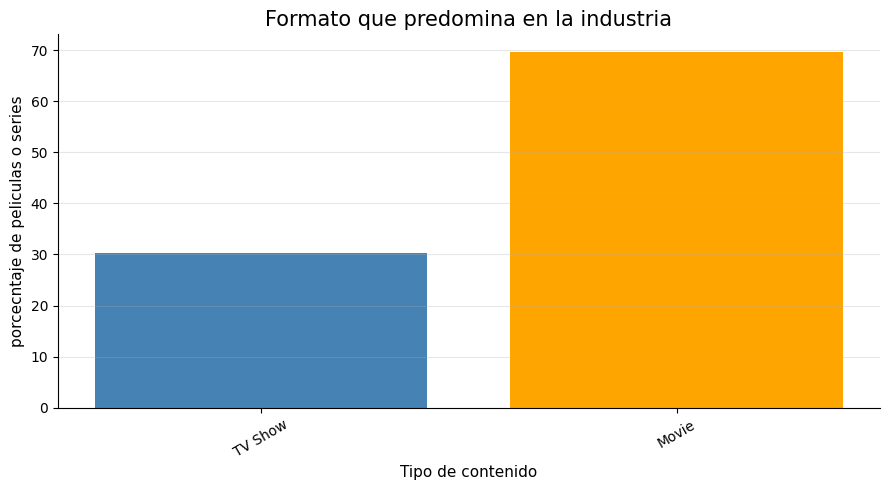

In [138]:
plt.figure(figsize=(9, 5))

colores = [
    "steelblue",
    "orange",
    "seagreen",
    "tomato"
]

plt.bar(
    pd_to_porcentaje["type"],
    pd_to_porcentaje["porcentaje"],
    color=colores
)

plt.title("Formato que predomina en la industria")
plt.xlabel("Tipo de contenido")
plt.ylabel("porcecntaje de peliculas o series")

plt.xticks(rotation=30)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

**Lectura para el negocio:** La oferta actual solo muestra variedad lo cual es bueno, pero justo muestra vairedad no preferencia del cleinte, es decir tener muchas pelis no asegura que los cleintes pidan mas pelis.

---
# Ejercicio 2/5: ¿Qué géneros se ofrecen dentro de cada formato?

**Pregunta:** ¿Cuáles son los géneros más representados entre películas y series?

**PySpark:** `withColumn`, `lower`, `contains`, `when`, `groupBy`, `avg`.

**Grafica:** barras agrupadas de porcentajes. Comparamos porcentajes **dentro de cada formato** para evitar que el grupo más grande domine todos los resultados.

Una pelicula o serie puede llevar varias etiquetas. Construiremos seis indicadores de géneros temáticos a partir de `listed_in`; los grupos **no son excluyentes**.

In [139]:
'''
NOTA: explode recibe una lista y regresa varias filas ej:
1)
type    genero_lista
Movie   [Dramas, Comedies]

despues ded explode
2)
type    genero
Movie   Dramas
Movie   Comedies
'''
TOTAL_MOVIES = 6131    # ponle el número que te salió
TOTAL_SHOWS  = 2676

print("generos para peliculas")
generos_peliculas = (
    df.where(F.col("type") == "Movie")
    .select("type", F.explode(F.split("listed_in", r",\s*")).alias("genero"))
    .groupBy("type", "genero")
    .agg(F.count("type").alias("cantidad"))
)
generos_peliculas.orderBy(F.col("cantidad").desc()).limit(5).show(truncate=False)

print("generos para series")
generos_series = (
    df.where(F.col("type") == "TV Show")
    .select("type", F.explode(F.split("listed_in", r",\s*")).alias("genero"))
    .groupBy("type", "genero")
    .agg(F.count("type").alias("cantidad"))
    .withColumn("porcentaje", F.round(100 * F.col("cantidad") / TOTAL_SHOWS, 2))
)
generos_series.orderBy(F.col("cantidad").desc()).limit(5).show(truncate=False)

generos para peliculas
+-----+--------------------+--------+
|type |genero              |cantidad|
+-----+--------------------+--------+
|Movie|International Movies|2752    |
|Movie|Dramas              |2427    |
|Movie|Comedies            |1674    |
|Movie|Documentaries       |869     |
|Movie|Action & Adventure  |859     |
+-----+--------------------+--------+

generos para series
+-------+----------------------+--------+----------+
|type   |genero                |cantidad|porcentaje|
+-------+----------------------+--------+----------+
|TV Show|International TV Shows|1351    |50.49     |
|TV Show|TV Dramas             |763     |28.51     |
|TV Show|TV Comedies           |581     |21.71     |
|TV Show|Crime TV Shows        |470     |17.56     |
|TV Show|Kids' TV              |451     |16.85     |
+-------+----------------------+--------+----------+



In [140]:
## scamos los porcentajes extra
## primero para peliculas
'''
NOTA: ya tengo un data frame de cantidades de eso los voy a harcodear
aca lo pude aver echo arriba pero estoy haciando experimentos
'''

df_generos_peliculas_porcentaje = generos_peliculas.withColumn("porcentaje", F.round(100 * F.col("cantidad") / TOTAL_MOVIES, 2))
df_generos_peliculas_porcentaje.orderBy(F.col("cantidad").desc()).limit(5).show()

+-----+--------------------+--------+----------+
| type|              genero|cantidad|porcentaje|
+-----+--------------------+--------+----------+
|Movie|International Movies|    2752|     44.89|
|Movie|              Dramas|    2427|     39.59|
|Movie|            Comedies|    1674|      27.3|
|Movie|       Documentaries|     869|     14.17|
|Movie|  Action & Adventure|     859|     14.01|
+-----+--------------------+--------+----------+



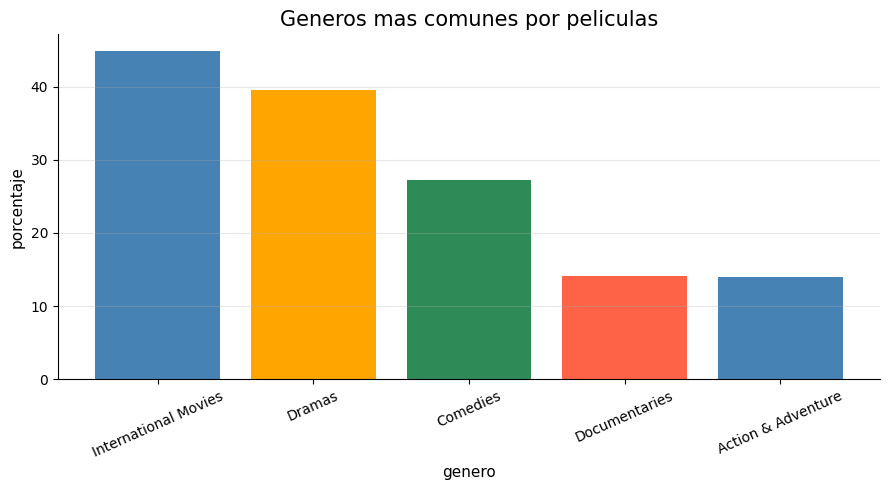

In [141]:
# Grafica 1plt.figure(figsize=(9, 5))

## convertimos a pandas
pd_peliculas_porcentaje = df_generos_peliculas_porcentaje.orderBy(F.col("cantidad").desc()).limit(5).toPandas()
pd_series_porcentaje = generos_series.orderBy(F.col("cantidad").desc()).limit(5).toPandas()

## graficamos para peliculas
plt.figure(figsize=(9, 5))

colores = [
    "steelblue",
    "orange",
    "seagreen",
    "tomato"
]

plt.bar(
    pd_peliculas_porcentaje["genero"],
    pd_peliculas_porcentaje["porcentaje"],
    color=colores
)

plt.title("Generos mas comunes por peliculas")
plt.xlabel("genero")
plt.ylabel("porcentaje")

plt.xticks(rotation=24)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


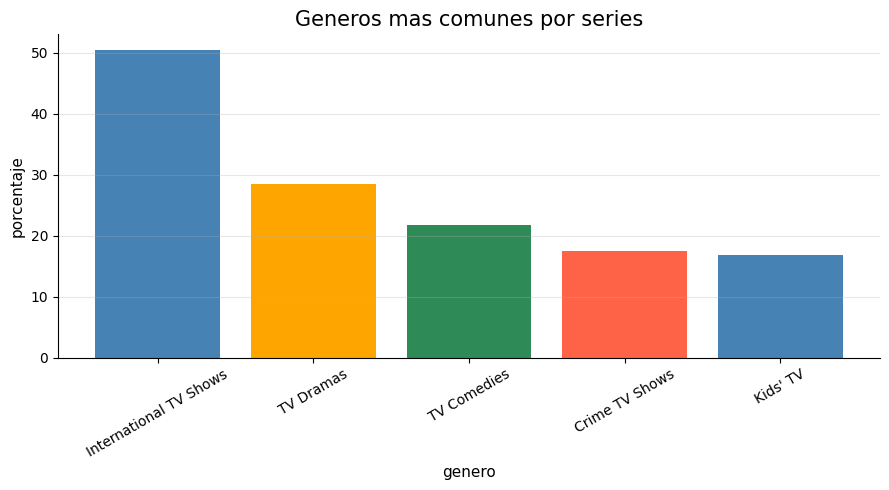

In [142]:
## graficamos para series
plt.figure(figsize=(9, 5))

colores = [
    "steelblue",
    "orange",
    "seagreen",
    "tomato"
]

plt.bar(
    pd_series_porcentaje["genero"],
    pd_series_porcentaje["porcentaje"],
    color=colores
)

plt.title("Generos mas comunes por series")
plt.xlabel("genero")
plt.ylabel("porcentaje")

plt.xticks(rotation=30)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


**Lectura para el negocio:** compara porcentajes del mismo género entre formatos. Los porcentajes **no suman 100%** porque una misma obra puede pertenecer a varias temáticas. La clasificación por coincidencia de palabras es una aproximacion didáctica.

---
# Ejercicio 3/5: ¿Cómo cambiaron las incorporaciones de películas y series?

**Pregunta:** Entre 2015 y 2020, cómo evolucionaron las altas de cada formato?

**PySpark:** fecha y año, `filter`, `between`, `groupBy`, `pivot`, `count`.

**Grafica:** dos series de tiempo. Excluimos 2021 porque la fuente solo cubre parte de ese año.

**Precaucion:** son fechas de incorporación de los títulos presentes en el dataset, no un registro histórico completo de altas y bajas.

In [143]:
altas = (
    df.where(F.col("anio_alta").between(2015, 2020))
      .groupBy("anio_alta")
      .pivot("type", ["Movie", "TV Show"])
      .agg(F.count("show_id"))
      .orderBy("anio_alta")
)
altas.show()

+---------+-----+-------+
|anio_alta|Movie|TV Show|
+---------+-----+-------+
|     2015|   56|     26|
|     2016|  253|    176|
|     2017|  839|    349|
|     2018| 1237|    412|
|     2019| 1424|    592|
|     2020| 1284|    595|
+---------+-----+-------+



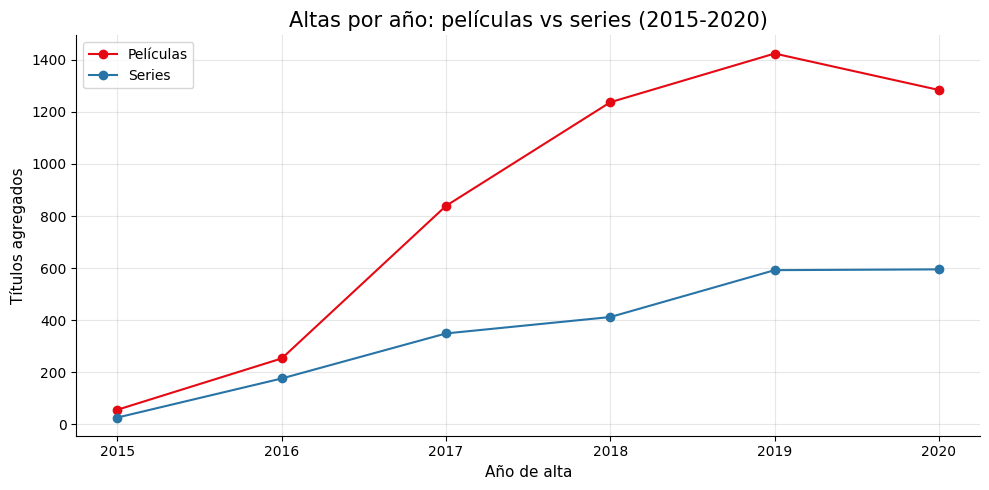

In [144]:
pdf = altas.fillna(0).toPandas()

plt.figure(figsize=(10, 5))
plt.plot(pdf["anio_alta"], pdf["Movie"], color=COLOR_MOVIE, marker="o", label="Películas")
plt.plot(pdf["anio_alta"], pdf["TV Show"], color=COLOR_SHOW, marker="o", label="Series")

plt.title("Altas por año: películas vs series (2015-2020)")
plt.xlabel("Año de alta")
plt.ylabel("Títulos agregados")
plt.xticks(pdf["anio_alta"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura para el negocio:** observa si la distancia entre las líneas cambia. El volumen anual describe el ritmo de incorporaciones en la muestra, pero no demuestra que creciera la demanda de un formato.

---
# Ejercicio 4/5: El catálogo recibe estrenos recientes o contenido antiguo?

**Pregunta:** En el momento de incorporar cada obra, cuántos años habian pasado desde su estreno?

**PySpark:** resta entre columnas, `filter`, `when`, `between`, `groupBy`, `pivot`.

**Grafica:** barras apiladas al 100% para comparar películas y series.

Definimos `antigüedad = anio_alta - release_year` y descartamos diferencias negativas o fechas faltantes. Esto describe la **frescura al incorporar**, no el envejecimiento actual del catálogo.

In [145]:
tramos = ["0-2", "3-5", "6-10", "11+"]

antig = (
    df.select("type", "show_id",
              (F.col("anio_alta") - F.col("release_year")).alias("antiguedad"))
      .where(F.col("antiguedad") >= 0)
      .select(
          "type", "show_id",
          F.when(F.col("antiguedad") <= 2, "0-2")
           .when(F.col("antiguedad") <= 5, "3-5")
           .when(F.col("antiguedad") <= 10, "6-10")
           .otherwise("11+")
           .alias("tramo")
      )
)

tabla = (
    antig.groupBy("type")
         .pivot("tramo", tramos)
         .agg(F.count("show_id"))
         .fillna(0)
)
tabla.show()

+-------+----+---+----+----+
|   type| 0-2|3-5|6-10| 11+|
+-------+----+---+----+----+
|TV Show|2009|308| 207| 130|
|  Movie|3531|811| 712|1075|
+-------+----+---+----+----+



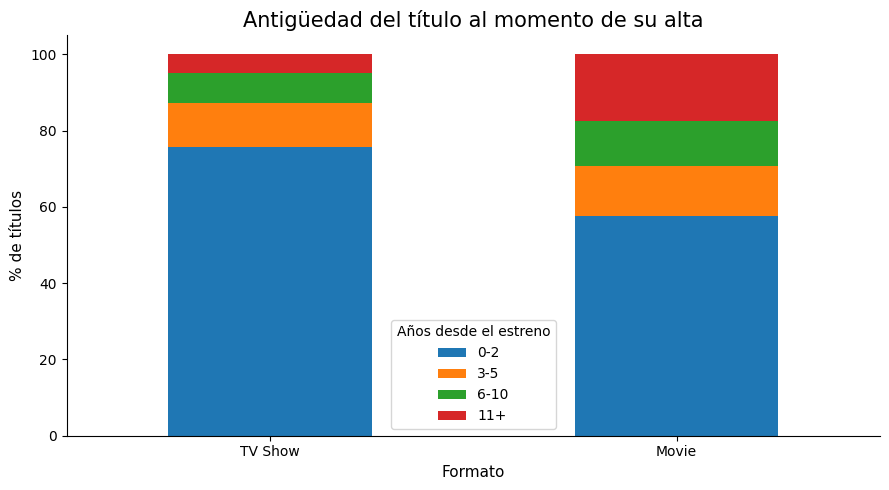

In [148]:
pdf = tabla.toPandas().set_index("type")[tramos]
pct = pdf.div(pdf.sum(axis=1), axis=0) * 100

ax = pct.plot(kind="bar", stacked=True, figsize=(9, 5))
ax.set_title("Antigüedad del título al momento de su alta")
ax.set_xlabel("Formato")
ax.set_ylabel("% de títulos")
ax.legend(title="Años desde el estreno")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Lectura para el negocio:** una proporción elevada del tramo de 0 a 2 años indica más contenido agregado cerca de su estreno. Los estrenos podrian ser atractivos, pero necesitamos conocer sus costes y reproducciones para estimar valor real.

---
# Ejercicio 5/5: ¿Qué tipo de contenido ganó importancia relativa?

**Pregunta:** Entre 2017-2018 y 2019-2020, qué géneros ganaron presencia dentro de cada formato?

**PySpark:** `filter`, `between`, `when`, `groupBy`, `count`, `avg`.

**Grafica:** mapa de calor (heatmap) con variacion en **puntos porcentuales**. Comparar proporciones, no volumen bruto, ayuda a detectar cambios en la mezcla editorial.

Un cambio positivo significa más **presencia relativa en las incorporaciones históricas que siguen en este dataset**. No significa más audiencia ni más rentabilidad.

In [152]:
generos_clave = {"drama": "drama", "comedia": "comed", "documental": "docu",
                 "terror": "horror", "accion": "action", "romance": "romant"}

exprs = [
    F.round(F.avg(F.when(F.lower("listed_in").contains(palabra), 1).otherwise(0)) * 100, 2).alias(nombre)
    for nombre, palabra in generos_clave.items()
]

por_periodo = (
    df.where(F.col("anio_alta").between(2017, 2020))
      .select("type", "listed_in",
              F.when(F.col("anio_alta") <= 2018, "2017-2018").otherwise("2019-2020").alias("periodo"))
      .groupBy("type", "periodo")
      .agg(*exprs)
)
por_periodo.show()

+-------+---------+-----+-------+----------+------+------+-------+
|   type|  periodo|drama|comedia|documental|terror|accion|romance|
+-------+---------+-----+-------+----------+------+------+-------+
|TV Show|2019-2020|27.63|  20.89|     14.24|  3.37|  6.99|  13.73|
|  Movie|2019-2020|40.58|  35.08|      11.3|  6.43| 13.74|  11.93|
|  Movie|2017-2018|39.69|  30.15|     17.97|  5.44| 13.01|   8.24|
|TV Show|2017-2018|31.41|  22.73|     15.77|  1.84|  4.86|  13.67|
+-------+---------+-----+-------+----------+------+------+-------+



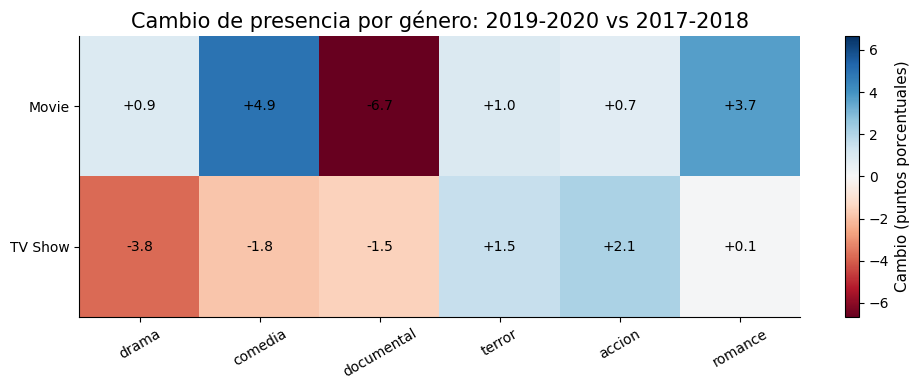

In [153]:
pdf = por_periodo.toPandas()
cols = list(generos_clave)

antes   = pdf[pdf["periodo"] == "2017-2018"].set_index("type")[cols]
despues = pdf[pdf["periodo"] == "2019-2020"].set_index("type")[cols]
matriz = despues - antes          # puntos porcentuales
categorias = cols

vmax = abs(matriz.values).max()

fig, ax = plt.subplots(figsize=(10, 4))

imagen = ax.imshow(
    matriz.values,
    aspect="auto",
    cmap="RdBu",
    vmin=-vmax,
    vmax=vmax
)

ax.set_xticks(range(len(categorias)))
ax.set_xticklabels(categorias, rotation=30)

ax.set_yticks(range(len(matriz.index)))
ax.set_yticklabels(matriz.index)

for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        ax.text(j, i, f"{matriz.values[i, j]:+.1f}", ha="center", va="center")

ax.set_title("Cambio de presencia por género: 2019-2020 vs 2017-2018")

plt.colorbar(imagen, label="Cambio (puntos porcentuales)")

plt.tight_layout()
plt.show()

# Propuesta de valor